# RAG over the FMLA Employer's Guide: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document:** *The Employer's Guide to the Family and Medical Leave Act* (U.S. Department of Labor, 76 pages), `data/GOVPUB-L-PURL-gpo84393.pdf`

**Two pipelines over the same chunks:**
- **Pipeline 1 (baseline):** bi-encoder retrieves the top 10 chunks, the top 3 go to the LLM, giving Answer 1.
- **Pipeline 2 (re-ranking):** the same top 10 are re-scored by a cross-encoder, the new top 3 go to the LLM with the same prompt, giving Answer 2.

**Notebook layout:**
1. Setup
2. Loading and cleaning the PDF
3. Chunking
4. Embeddings and vector store
5. Pipeline 1
6. Pipeline 2
7. Failure-mode analysis
8. Latency
9. Scaling

## Step 1: Setup

Install the packages, import them, and check that the Gemini API key works.

- The retrieval models (bi-encoder and cross-encoder) run locally on the CPU.
- Only the answer generation calls the Gemini API.

In [1]:
# Install packages into the same environment this notebook runs in (%pip, not !pip).
# torch comes from PyTorch's CPU-only index: this laptop has no GPU, and the default
# CUDA build is several GB (the first install attempt timed out downloading it).
%pip install -q --no-cache-dir --default-timeout=120 torch --index-url https://download.pytorch.org/whl/cpu
%pip install -q --no-cache-dir --default-timeout=120 -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import platform

import numpy as np
import pandas as pd
import torch
import pymupdf                 # PyMuPDF: extracts text from the PDF
import faiss                   # vector index for similarity search
import sentence_transformers
from sentence_transformers import SentenceTransformer, CrossEncoder
from google import genai
from google.genai import types
from dotenv import load_dotenv

# Record the environment so the results can be reproduced later
print("python               ", platform.python_version())
print("torch                ", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("CPU threads used     ", torch.get_num_threads())
print("pymupdf              ", pymupdf.__version__)
print("faiss                ", faiss.__version__)
print("sentence-transformers", sentence_transformers.__version__)
print("numpy / pandas       ", np.__version__, "/", pd.__version__)

python                3.12.3
torch                 2.14.1+cpu | CUDA available: False
CPU threads used      10
pymupdf               1.28.2
faiss                 1.15.1
sentence-transformers 6.1.0
numpy / pandas        2.4.3 / 3.0.1


In [3]:
# Paths used throughout the notebook
DATA_PDF = "data/GOVPUB-L-PURL-gpo84393.pdf"
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

assert os.path.exists(DATA_PDF), "PDF not found - run the notebook from the repo root"
print("PDF size: %.1f MB" % (os.path.getsize(DATA_PDF) / 1e6))

PDF size: 5.2 MB


In [4]:
# The API key lives in .env (never committed; see .gitignore).
# load_dotenv() copies the lines of .env into environment variables.
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")
assert api_key, "GEMINI_API_KEY missing - add it to a .env file in the repo root"

# Retry automatically on temporary server errors (429 rate limit, 503 "high demand", other 5xx),
# waiting about 2 s, 4 s, 8 s, ... between attempts. Both kinds of error happened while building this.
client = genai.Client(
    api_key=api_key,
    http_options=types.HttpOptions(
        retry_options=types.HttpRetryOptions(attempts=6, initial_delay=2.0, max_delay=60.0)),
)

# Model names change over time, so list the Flash models this key can call
# (speech "tts" and "image" models are skipped: we only need text answers)
flash_models = [
    m.name for m in client.models.list()
    if "flash" in m.name and "generateContent" in (m.supported_actions or [])
    and "tts" not in m.name and "image" not in m.name
]
print(len(flash_models), "Flash models available:")
for name in flash_models:
    print("  ", name)

14 Flash models available:
   models/gemini-2.5-flash
   models/gemini-flash-latest
   models/gemini-flash-lite-latest
   models/gemini-2.5-flash-lite
   models/gemini-3-flash-preview
   models/gemini-3.1-flash-lite-preview
   models/gemini-3.1-flash-lite
   models/gemini-3.5-flash
   models/gemini-3.5-flash-lite
   models/gemini-omni-flash-preview
   models/gemini-omni-1.1-flash
   models/gemini-3.6-flash
   models/gemini-3.7-flash
   models/gemini-3.8-flash


In [5]:
import time

# One model for the whole notebook, so both pipelines use exactly the same LLM.
# (gemini-2.5-flash is no longer offered to new API keys.)
GEMINI_MODEL = "gemini-3.8-flash"
assert "models/" + GEMINI_MODEL in flash_models, "model not available for this key"

# Smoke test: one tiny request to confirm the key and model work
start = time.perf_counter()
reply = client.models.generate_content(
    model=GEMINI_MODEL,
    contents="Say hello in five words.",
    config=types.GenerateContentConfig(temperature=0),
)
elapsed = time.perf_counter() - start

usage = reply.usage_metadata
print("model          :", GEMINI_MODEL)
print("reply          :", reply.text.strip())
print("time           : %.1f s" % elapsed)
print("prompt tokens  :", usage.prompt_token_count)
print("answer tokens  :", usage.candidates_token_count)
print("thinking tokens:", usage.thoughts_token_count)

model          : gemini-3.8-flash
reply          : Hello there, how are you?
time           : 5.4 s
prompt tokens  : 7
answer tokens  : 7
thinking tokens: 362


## Step 2: Loading and cleaning the PDF

PyMuPDF gives every piece of text with its position and font. We use those signals to keep only real content:

- **Skip** the cover, disclaimer and table of contents (pp. 1-5), a full-page flowchart (p. 8), the index (pp. 72-75) and the back cover (p. 76).
- **Drop** the running header (above y = 90 pt) and footer (below y = 748 pt). The chapter name is read from the header first, because it exists only there.
- **Drop** comic speech bubbles and diagram labels (condensed fonts, 9 pt text, or tiny labels).
  - Known cost: the next-of-kin priority list on p. 42 exists only inside a diagram, so it is lost.
- **Keep** "DID YOU KNOW?" boxes, examples and footnotes. They hold the exceptions we want to test.
- **Very short blocks** (5 words or fewer) are not paragraphs on their own:
  - a sentence tail ("Defense.") is attached to the previous paragraph;
  - a label or lead-in ("Spouse", "DID YOU KNOW?", "The employer cannot refuse:") is attached to the next one.
- **Normalise** characters (ligatures, curly quotes, bullets).

Each paragraph keeps its page, chapter and section heading as metadata.

In [6]:
import re
import string
import unicodedata

# Pages without real content: cover, disclaimer and contents (1-5), full-page flowchart (8),
# index (72-75) and back cover (76)
SKIP_PAGES = {1, 2, 3, 4, 5, 8, 72, 73, 74, 75, 76}

# Pages are 612 x 792 pt and y grows downwards. The running header sits above y=90 and the
# footer below y=748; body text always lies in between (measured: y=115 to y=745).
HEADER_Y, FOOTER_Y = 90, 748


def is_illustration(span):
    """Comic speech bubbles and diagram labels use condensed fonts, 9 pt text or tiny labels;
    a few tables use huge (40 pt) 'X' symbols as tick marks."""
    return ("Cond" in span["font"] or 8.9 <= span["size"] <= 9.2
            or span["size"] < 7 or span["size"] > 24)


def clean_text(text):
    """Normalise characters so the text matches what a user would type."""
    text = unicodedata.normalize("NFKC", text)                   # ligature 'fi' -> 'f' + 'i'
    text = text.replace("\u2019", "'").replace("\u2018", "'")    # curly -> straight quotes
    text = text.replace("\u201c", '"').replace("\u201d", '"')
    text = re.sub(r"\u2022\s*", "\u2022 ", text)                 # bullet + tab -> bullet + space
    return re.sub(r"\s+", " ", text).strip()                     # line breaks -> single spaces


def read_chapter(page):
    """Read the chapter name from the running header, e.g. 'Chapter 2: When An Employee Needs FMLA Leave'."""
    spans = [s for b in page.get_text("dict", sort=True)["blocks"]
             for line in b.get("lines", []) for s in line["spans"]
             if s["text"].strip() and s["bbox"][1] < HEADER_Y]
    header = clean_text(" ".join(s["text"] for s in spans))
    title = clean_text(" ".join(s["text"] for s in spans if s["size"] >= 18))   # 20 pt title
    title = string.capwords(title.lower()).replace("Fmla", "FMLA")
    number = re.search(r"CHAPTER\s*(\d+)", header)
    return f"Chapter {number.group(1)}: {title}" if number else title

In [7]:
def block_to_text(block, removed):
    """Join the spans of one text block that survive the filters, line by line.

    Returns (text, largest font size), or (None, 0) if nothing in the block survives.
    `removed` counts the dropped spans by reason.
    """
    lines, max_size = [], 0
    for line in block.get("lines", []):
        parts = []
        for span in line["spans"]:
            if not span["text"].strip():          # whitespace-only span: keep as a separator
                parts.append(" ")
                continue
            if span["bbox"][1] < HEADER_Y or span["bbox"][1] > FOOTER_Y:
                removed["header/footer"] += 1
                continue
            if is_illustration(span):
                removed["illustration"] += 1
                continue
            parts.append(span["text"])
            max_size = max(max_size, span["size"])
        line_text = "".join(parts).strip()
        if line_text:
            lines.append(line_text)
    if not lines:
        return None, 0

    # Join the lines with spaces. A line ending in '-' ("FMLA-" + "protected") is joined without one.
    text = lines[0]
    for nxt in lines[1:]:
        text = text + nxt if text.endswith("-") else text + " " + nxt
    return clean_text(text), max_size

In [8]:
doc = pymupdf.open(DATA_PDF)
removed = {"header/footer": 0, "illustration": 0}
paragraphs = []
chapter, section = None, None
label = ""                # a short label / lead-in waiting to be glued to the next paragraph


def add_paragraph(page_no, text):
    paragraphs.append({"page": page_no, "chapter": chapter, "section": section, "text": text})


for page in doc:
    page_no = page.number + 1
    if page_no in SKIP_PAGES:
        continue

    page_chapter = read_chapter(page)            # read the header BEFORE it is dropped
    if page_chapter != chapter:                  # new chapter: text before its first heading
        chapter, section = page_chapter, page_chapter   # belongs to the chapter in general

    for block in page.get_text("dict", sort=True)["blocks"]:   # sort=True -> reading order
        text, size = block_to_text(block, removed)
        if text is None:
            continue

        # Section headings are 14-16 pt and not ALL CAPS ("DID YOU KNOW?" and the diagram
        # title "12 MONTH LOOK BACK" are capitals). Keep them as metadata, not as paragraphs.
        if 14 <= size <= 17 and not text.isupper():
            if label:                            # a dangling label stays as its own paragraph
                add_paragraph(page_no, label)
                label = ""
            section = text
            continue

        # Very short blocks (<= 5 words) are not paragraphs on their own
        if len(text.split()) <= 5:
            if text.endswith(".") and paragraphs:     # tail of the previous sentence
                paragraphs[-1]["text"] += " " + text
            else:                                     # label / lead-in for the next paragraph
                label = (label + " " + text).strip()
            continue

        if label:
            text, label = label + " " + text, ""
        add_paragraph(page_no, text)

paras = pd.DataFrame(paragraphs)
paras["n_words"] = paras["text"].str.split().str.len()

print(f"{len(paras)} paragraphs from {paras['page'].nunique()} pages, {paras['section'].nunique()} sections")
print("spans removed:", removed)
paras.head(8)

474 paragraphs from 65 pages, 100 sections
spans removed: {'header/footer': 326, 'illustration': 269}


,page,chapter,section,text,n_words
0,6,Introduction,Introduction,The Family and Medical Leave Act (FMLA) is a f...,50
1,6,Introduction,Introduction,• The birth of a son or daughter or placement ...,122
2,6,Introduction,Introduction,An eligible employee may also take up to 26 wo...,157
3,6,Introduction,Introduction,The U.S. Department of Labor's Wage and Hour D...,47
4,6,Introduction,Introduction,The Wage and Hour Division is committed to str...,110
5,6,Introduction,Introduction,The Department of Labor is providing this Guid...,92
6,7,Introduction,Introduction,Visit the Department's website for resources c...,12
7,7,Introduction,Introduction,• Key News • General Guidance • The Employee's...,47


In [9]:
# How much text did cleaning remove?
raw_words_all = sum(len(p.get_text().split()) for p in doc)
raw_words_kept_pages = sum(len(doc[int(p) - 1].get_text().split()) for p in paras["page"].unique())
print(f"words in the whole PDF          : {raw_words_all:6d}")
print(f"words on the pages we keep (raw): {raw_words_kept_pages:6d}")
print(f"words after cleaning            : {paras['n_words'].sum():6d}")

# Paragraphs and words per chapter
per_chapter = paras.groupby("chapter", sort=False).agg(
    pages=("page", "nunique"), paragraphs=("text", "size"), words=("n_words", "sum"))
display(per_chapter)

# Paragraph length distribution (in words): Step 3 builds chunks from these
print(paras["n_words"].describe().round(1).to_string())

words in the whole PDF          :  26537
words on the pages we keep (raw):  24454
words after cleaning            :  22319


,pages,paragraphs,words
chapter,,,
Introduction,2,8,637
Chapter 1: Covered Employers Under The FMLA And Their General Notice Requirements,5,38,1468
Chapter 2: When An Employee Needs FMLA Leave,9,61,3239
Chapter 3: Qualifying Reasons For Leave,5,38,1603
Chapter 4: The Certification Process,9,79,3008
Chapter 5: Military Family Leave,10,63,2726
Chapter 6: During An Employee's FMLA Leave,24,175,9281
Chapter 7: FMLA Prohibitions,1,12,357


count    474.0
mean      47.1
std       35.1
min        6.0
25%       19.0
50%       41.0
75%       63.0
max      212.0


In [10]:
# Sanity checks: the notebook stops here if cleaning went wrong
all_text = " ".join(paras["text"])

# The footer is the guide's title followed by the page number ("... Medical Leave Act 17").
# The title alone appears once as real content: page 7 lists it among the DoL resources.
assert not re.search(r"Medical Leave Act \d{1,2}\b", all_text), "footer left in"
assert all_text.count("The Employer's Guide to the Family and Medical Leave Act") == 1
assert not any(s in all_text for s in ["Bobby:", "Brenda (on phone)", "Jan 2015 Feb"]), "comic/diagram text left in"
assert not any(ch in all_text for ch in ["\u2018", "\u2019", "\u201c", "\u201d", "\ufb01"]), "special characters left in"

kept_pages = set(range(1, doc.page_count + 1)) - SKIP_PAGES
missing = kept_pages - set(paras["page"])
assert not missing, f"pages without any paragraph: {sorted(missing)}"
assert paras["chapter"].notna().all() and paras["section"].notna().all()

# Headings must be real section titles (no box titles, diagram titles or table symbols)
assert not any(s.isupper() or s.endswith(" X") for s in paras["section"].unique())

# We must not over-clean: the 'DID YOU KNOW?' box on page 17 has to survive, glued to its title
# (regex=False: in a regular expression the "?" would mean "the W is optional")
assert paras["text"].str.contains("DID YOU KNOW? An employer has the burden of showing", regex=False).any()
assert (paras["n_words"] > 5).all(), "short labels should have been merged"

print("all checks passed")

all checks passed


In [11]:
# Before / after for page 17
print("RAW (PyMuPDF default text, first 700 characters):\n")
print(doc[16].get_text()[:700])
print("\n" + "=" * 80 + "\nCLEANED paragraphs of page 17:\n")
for _, row in paras[paras["page"] == 17].iterrows():
    print(f"[{row['section']}]  {row['text'][:160]}{'...' if len(row['text']) > 160 else ''}\n")

RAW (PyMuPDF default text, first 700 characters):

The Employer’s Guide to the Family and Medical Leave Act
17
1,250 Hours of Service
The hours of service requirement will be met if an employee has worked a total of 1,250 hours of service 
in the 12 months immediately preceding the start of the FMLA leave. This averages to a little more than 24 
hours of work a week in the 12-month period.
•	 Generally, the principles for compensable hours of work under the Fair Labor Standards Act (FLSA) 
are used in determining the hours of service that an employee has worked. 
•	 Only the time actually worked, including overtime hours worked, is counted. Time not actually 
worked, including vacation, personal leave, sick leave, holidays, and any other for

CLEANED paragraphs of page 17:

[1,250 Hours of Service]  The hours of service requirement will be met if an employee has worked a total of 1,250 hours of service in the 12 months immediately preceding the start of the...

[1,250 Hours of Service]

## Step 3: Chunking

Chunks are what gets embedded, retrieved and shown to the LLM.

- **Sizes are counted in tokens** with the bi-encoder's own tokenizer, because its limit is 256 tokens. Anything longer is silently cut off.
- **Recipe:**
  - pack whole sentences and bullet items, up to **200 tokens** per chunk (heading included);
  - repeat up to **40 tokens** of whole sentences at the start of the next chunk (overlap);
  - never cross a section boundary;
  - start every chunk with its section heading (a "contextual chunk header").
- **Repair first:** paragraphs that PyMuPDF split in the middle of a sentence are re-joined before splitting into sentences.

The chunks are saved to `results/chunks.csv` (used later to find the gold chunk for each test query).

In [12]:
from transformers import AutoTokenizer

BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"
CHUNK_TOKENS = 200       # max tokens per chunk, heading included
OVERLAP_TOKENS = 40      # max tokens of whole sentences repeated from the previous chunk
MODEL_MAX_TOKENS = 256   # bi-encoder input limit (including [CLS] and [SEP])

# Count tokens with the bi-encoder's own tokenizer, so "fits" is guaranteed
tokenizer = AutoTokenizer.from_pretrained(BI_ENCODER_NAME)


def n_tokens(text):
    return len(tokenizer.tokenize(text))


print("vocabulary size:", tokenizer.vocab_size, "| lower-cases text:", tokenizer.do_lower_case)
for word in ["FMLA", "servicemember", "in loco parentis", "recertification"]:
    print(f"  {word!r:20} -> {tokenizer.tokenize(word)}")

vocabulary size: 30522 | lower-cases text: True
  'FMLA'               -> ['fm', '##la']
  'servicemember'      -> ['service', '##me', '##mber']
  'in loco parentis'   -> ['in', 'loco', 'parent', '##is']
  'recertification'    -> ['rec', '##ert', '##ification']


In [13]:
def rejoin_fragments(paras):
    """Glue a paragraph that stops mid-sentence to the next one.

    PyMuPDF sometimes puts indented sub-bullets in separate blocks, even in the middle of a
    sentence. Rule: if a paragraph does not end with . ! ? : ; and the next paragraph of the same
    section starts with a lower-case letter, they belong together.
    """
    rows = []
    for row in paras.to_dict("records"):
        prev = rows[-1] if rows else None
        if (prev is not None and prev["section"] == row["section"]
                and not re.search(r"[.!?:;]\s*$", prev["text"])
                and re.match(r"[a-z]", row["text"])):
            prev["text"] += " " + row["text"]
            prev["pages"] = sorted(set(prev["pages"]) | {row["page"]})
        else:
            rows.append({**row, "pages": [row["page"]]})
    return pd.DataFrame(rows).drop(columns=["page", "n_words"])


paras_joined = rejoin_fragments(paras)
print(f"{len(paras)} paragraphs -> {len(paras_joined)} after re-joining {len(paras) - len(paras_joined)} fragments")

474 paragraphs -> 459 after re-joining 15 fragments


In [14]:
BULLET = chr(0x2022)   # the bullet character (U+2022)

# A new sentence starts after . ! ? ; : when the next piece begins like a sentence or list item.
SENTENCE_BREAK = re.compile(r"(?<=[.!?;:])\s+(?=[A-Z\"(-]|" + BULLET + ")")
# Bullet items ("• ...") and sub-bullets ("-- ...") always start a new piece.
ITEM_BREAK = re.compile(r"\s+(?=" + BULLET + " |-- )")


def split_sentences(text):
    """Split a paragraph into sentences and list items."""
    pieces = []
    for part in ITEM_BREAK.split(text):
        pieces += SENTENCE_BREAK.split(part)
    return [p.strip() for p in pieces if p.strip()]


def overlap_tail(sentences, max_tokens):
    """The last whole sentences of a chunk whose total length is at most max_tokens."""
    tail = []
    for sent in reversed(sentences):
        if n_tokens(" ".join([sent] + tail)) > max_tokens:
            break
        tail.insert(0, sent)
    return tail


def chunk_section(heading, units):
    """Pack the (sentence, pages) units of one section into chunks of at most CHUNK_TOKENS.

    Every chunk starts with "heading: ". When a chunk is full, the next one starts with up to
    OVERLAP_TOKENS of the previous chunk's last whole sentences.
    """
    header = heading + ": "
    budget = CHUNK_TOKENS - n_tokens(header)
    chunks, current = [], []
    for unit in units:
        assert n_tokens(unit[0]) <= budget, f"sentence longer than a chunk: {unit[0][:80]}"
        if current and n_tokens(" ".join(u[0] for u in current + [unit])) > budget:
            chunks.append(current)
            tail = overlap_tail([u[0] for u in current], OVERLAP_TOKENS)
            current = current[len(current) - len(tail):] if tail else []
            # the overlap must still leave room for the new sentence
            while current and n_tokens(" ".join(u[0] for u in current + [unit])) > budget:
                current = current[1:]
        current.append(unit)
    if current:
        chunks.append(current)
    return [(header + " ".join(u[0] for u in c), sorted({p for u in c for p in u[1]})) for c in chunks]

In [15]:
rows = []
for (chapter, section), group in paras_joined.groupby(["chapter", "section"], sort=False):
    units = [(sent, row["pages"]) for row in group.to_dict("records") for sent in split_sentences(row["text"])]
    for text, pages in chunk_section(section, units):
        rows.append({"chapter": chapter, "section": section,
                     "pages": ", ".join(str(p) for p in pages), "text": text})

chunks = pd.DataFrame(rows)
chunks.insert(0, "chunk_id", range(len(chunks)))
chunks["n_tokens"] = chunks["text"].map(n_tokens)

chunks.to_csv(os.path.join(RESULTS_DIR, "chunks.csv"), index=False)
print(f"{len(chunks)} chunks saved to {RESULTS_DIR}/chunks.csv")
print("tokens per chunk:", chunks["n_tokens"].describe().round(1).to_dict())
print("chunks per section:", chunks.groupby(["chapter", "section"]).size().value_counts().sort_index().to_dict())
extra = chunks["n_tokens"].sum() / paras["text"].map(n_tokens).sum() - 1
print(f"tokens in all chunks vs. cleaned text: +{extra:.0%} (overlap + headings)")
chunks.head()

207 chunks saved to results/chunks.csv
tokens per chunk: {'count': 207.0, 'mean': 150.6, 'std': 46.4, 'min': 27.0, '25%': 121.5, '50%': 170.0, '75%': 188.0, 'max': 200.0}
chunks per section: {1: 48, 2: 20, 3: 19, 4: 7, 5: 2, 6: 4}
tokens in all chunks vs. cleaned text: +14% (overlap + headings)


,chunk_id,chapter,section,pages,text,n_tokens
0,0,Introduction,Introduction,6,Introduction: The Family and Medical Leave Act...,173
1,1,Introduction,Introduction,6,Introduction: • For a serious health condition...,167
2,2,Introduction,Introduction,6,Introduction: An eligible employee is limited ...,193
3,3,Introduction,Introduction,6,"Introduction: In most instances, an employee a...",190
4,4,Introduction,Introduction,"6, 7",Introduction: The Department of Labor is provi...,199


In [16]:
# Sanity checks
# 1. Nothing is silently truncated: [CLS] + chunk + [SEP] must fit the bi-encoder
lengths_with_special = chunks["text"].map(lambda t: len(tokenizer(t)["input_ids"]))
assert lengths_with_special.max() <= MODEL_MAX_TOKENS, lengths_with_special.max()

# 2. No text is lost: every sentence of every paragraph is in at least one chunk of its section
for (chapter, section), group in paras_joined.groupby(["chapter", "section"], sort=False):
    section_text = " ".join(chunks[(chunks["chapter"] == chapter) & (chunks["section"] == section)]["text"])
    for row in group.to_dict("records"):
        for sent in split_sentences(row["text"]):
            assert sent in section_text, f"lost: {sent[:80]}"

# 3. The sentence that PyMuPDF had split over three blocks on page 16 is whole again
assert chunks["text"].str.contains("prior to a break of more than seven years, but it must do so uniformly", regex=False).any()

# 4. Every chunk starts with its heading, ids are unique
assert all(t.startswith(s + ": ") for t, s in zip(chunks["text"], chunks["section"]))
assert chunks["chunk_id"].is_unique

print(f"all checks passed (longest chunk incl. [CLS]/[SEP]: {lengths_with_special.max()} tokens)")

all checks passed (longest chunk incl. [CLS]/[SEP]: 202 tokens)


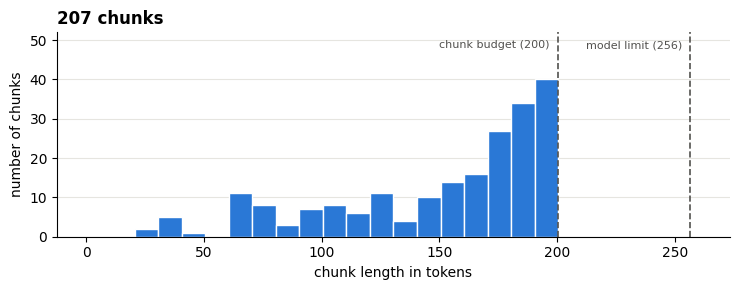

--- chunk 140 | p. 53 | 179 tokens
Spouses Working for the Same Employer: Eligible spouses who work for the same employer are limited to a combined total of 12 workweeks of leave in a 12-month period to share for the following FMLA-qualifying reasons: • The birth of a son or daughter and bonding with the newborn child, • The placement of a son or daughter with the employee for adoption or foster care, and bonding with the newly-placed child, and • The care of a parent with a serious health condition. Eligible spouses who work for the same employer are also limited to a combined total of 26 workweeks in a single 12-month period to care for a covered servicemember with a serious injury or illness if each spouse is a parent, spouse, son or daughter, or next of kin of the servicemember (commonly referred to as "military caregiver leave").

--- chunk 141 | p. 53, 54 | 176 tokens
Spouses Working for the Same Employer: This limitation also applies to a combination of military caregiver leave 

In [17]:
import matplotlib.pyplot as plt

FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Histogram of chunk lengths with the chunk budget and the model limit
# Bin edges sit at x.5 so that a chunk of exactly 200 tokens falls in the bar that ends at 200
fig, ax = plt.subplots(figsize=(7.5, 3))
counts, _, _ = ax.hist(chunks["n_tokens"], bins=np.arange(0.5, 261, 10), color="#2a78d6", edgecolor="white")
ax.set_ylim(0, counts.max() * 1.3)                     # headroom for the labels
for x, label in [(CHUNK_TOKENS, "chunk budget (200)"), (MODEL_MAX_TOKENS, "model limit (256)")]:
    ax.axvline(x + 0.5, color="#52514e", linestyle="--", linewidth=1.2)
    ax.text(x - 3, counts.max() * 1.25, label, ha="right", va="top", fontsize=8, color="#52514e")
ax.set_xlabel("chunk length in tokens")
ax.set_ylabel("number of chunks")
ax.set_title(f"{len(chunks)} chunks", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "chunk_lengths.png"), dpi=150)
plt.show()

# Two example chunks
for section in ["Spouses Working for the Same Employer", "Limitations on an Employee's Right to Return to Work"]:
    for _, c in chunks[chunks["section"] == section].head(2).iterrows():
        print(f"--- chunk {c.chunk_id} | p. {c.pages} | {c.n_tokens} tokens\n{c.text}\n")